# Practical Lab — Building AI Agents with LangGraph

**Course:** Advanced Artificial Intelligence / Generative AI 
**Attendees** PHD Students.
**Technology:** Python, LangChain, LangGraph, LLM APIs  
**Level:** Intermediate | **Format:** Jupyter Notebook

## 1. Lab objectives

At the end of this lab, you should be able to:

- Explain the difference between a conventional LLM chain and an agentic workflow.
- Understand the main LangGraph concepts: **State, Nodes, Edges, Conditional edges, Graph execution**.
- Build a simple conversational agent and add memory/state to it.
- Implement conditional routing and integrate tools.
- Build a multi-step research-style agent that can decide which action to perform.
- Visualize and test the resulting graph, and evaluate its behavior.

> **Tip:** Write your answers to the conceptual questions in the *"Your answer"* cells. They form part of your final report.

## PART I — Environment setup
### Exercise 1 — Install LangGraph

In [1]:
%pip install -U langgraph langchain langchain-openai langchain-community

  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
   ---------------------------------------- 0.0/575.5 kB ? eta -:--:--
   ---------------------------------------- 575.5/575.5 kB 10.2 MB/s  0:00:00
   ---------------------------------------- 0.0/911.8 kB ? eta -:--:--
   ---------------------------------------- 911.8/911.8 kB 9.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 20.8 MB/s  0:00:00
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ----------------------------------- ---- 2.1/2.4 MB 12.2 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 9.1 MB/s  0:00:00
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 15.6 MB/s  0:00:00
   ---------------------------------------- 0.0/2.4 MB ? eta

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\Imane SAMIR\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
from importlib.metadata import version

print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))

LangGraph: 1.2.18
LangChain: 1.4.7


### Question
What is the role of:
1. **LangChain?**
2. **LangGraph?**
3. **An LLM?**

**Your answer:**  
1. *LangChain:*  It is a platform that makes it easier to develop applications using LLMs. It offers components such as model wrappers, prompt templates, tools, output parsers, and chains to easily connect an LLM to various data sources, APIs and functions.
2. *LangGraph:*  is a library that sits on top of LangChain to coordinate stateful workflows of agents as a graph. The nodes are the tasks while the edges represent the flow, and the conditional edges allow branching, looping, or tool invocation based on the shared state. 
3. *LLM:* It is the language model that lies at the heart of the agent. It processes text, thinks about it, and produces responses. Inside an agent it is the "brain" that determines how to respond or which tool to use, but by itself it has no memory, tools or control flow. That is what LangChain and LangGraph provide.

## PART II — First LangGraph workflow
### Exercise 2 — Understanding State

In LangGraph, the **state** represents the information shared between nodes.

In [3]:
from typing import TypedDict

class AgentState(TypedDict):
    message: str
    response: str

In [4]:
def process_message(state: AgentState):
    message = state["message"]
    response = f"Agent received: {message}"
    return {"response": response}

In [5]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)
graph_builder.add_node("process", process_message)
graph_builder.add_edge(START, "process")
graph_builder.add_edge("process", END)

graph = graph_builder.compile()

In [6]:
result = graph.invoke({
    "message": "Hello LangGraph!",
    "response": ""
})
print(result)

{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}


**Expected result**
```python
{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}
```

### Questions
1. What is a node?
2. What is an edge?
3. What is `START`?
4. What is `END`?
5. Why is the state passed between nodes?

**Your answer:**  
1. *Node:* is a unit of work in the graph and is typically a Python function. It takes in the current state, performs an action (call an LLM, run a tool, perform some transformation), and returns a dictionary containing the state fields that it wishes to update. In this lab, process_message is a node.  
2. *Edge:* is a connection between two nodes that shows the order in which things happen. After node A is done the process moves to node B. Edges can be set in a fixed way using `add_edge`. They can be based on conditions using `add_conditional_edges`. With conditions a function decides which node comes next based on the state.  
3. *`START`:*  is the designated entry point for the graph. It is not an actual node. Edges that originate at `START` inform LangGraph of the starting node.
4. *`END`:* is the special terminal point of the graph. When the flow reaches `END`, execution stops and the final state is returned. 
5. *The state is passed between nodes* because it is the shared memory of the workflow. Each node reads what previous nodes produced (for example the analysis, the category, or the messages) and writes its own result. Nodes stay independent and do not call each other directly, and the full state at the end is the output of the graph.

## PART III — Building an LLM Agent
### Exercise 3 — Connect an LLM

**Do not hard-code the API key in the notebook.** Prefer an environment variable configured outside the notebook; otherwise prompt for it securely as below.

In [11]:
import requests

models = requests.get("https://openrouter.ai/api/v1/models").json()["data"]
free_tools = [m["id"] for m in models
              if m["id"].endswith(":free")
              and "tools" in (m.get("supported_parameters") or [])]

print(len(free_tools), "free models with tool calling:")
for m in free_tools:
    print(" ", m)

15 free models with tool calling:
  recursive/flint-v1.0:free
  xingchen-agi/xing4.0-29b-a4b:free
  nvidia/nemotron-3.5-super-vl:free
  dots-studio/dots-3-note-preview:free
  liquid/lfm-2.5-2.6b:free
  nvidia/nemotron-3.5-lightning:free
  thinkingmachines/inkling-small:free
  poolside/laguna-s-2.1:free
  thinkingmachines/inkling:free
  poolside/laguna-xs-2.1:free
  cohere/north-mini-code:free
  nvidia/nemotron-3-ultra-550b-a55b:free
  nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free
  google/gemma-4-26b-a4b-it:free
  google/gemma-4-31b-it:free


In [14]:
import os, requests
from getpass import getpass
from langchain_openai import ChatOpenAI

if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass("Enter your OpenRouter API key: ")

models = requests.get("https://openrouter.ai/api/v1/models").json()["data"]
candidates = [m["id"] for m in models
              if m["id"].endswith(":free")
              and "tools" in (m.get("supported_parameters") or [])]
print(len(candidates), "free models with tool calling")

working = []
for mid in candidates[:10]:
    try:
        test = ChatOpenAI(model=mid, base_url="https://openrouter.ai/api/v1",
                          api_key=os.environ["OPENROUTER_API_KEY"],
                          temperature=0, max_retries=0)
        out = test.invoke("Say hello in one short sentence.").content
        print("OK  ", mid, "->", out[:60].replace("\n", " "))
        working.append(mid)
    except Exception as e:
        print("FAIL", mid, type(e).__name__)

print("\nWorking models:", working)

15 free models with tool calling
OK   recursive/flint-v1.0:free -> Hello!
OK   xingchen-agi/xing4.0-29b-a4b:free -> Hello!
OK   nvidia/nemotron-3.5-super-vl:free -> Hello!
OK   dots-studio/dots-3-note-preview:free ->   Hello! I'm here to help.
FAIL liquid/lfm-2.5-2.6b:free OpenAIRateLimitError
OK   nvidia/nemotron-3.5-lightning:free -> Hello!
FAIL thinkingmachines/inkling-small:free OpenAIPermissionDeniedError
FAIL poolside/laguna-s-2.1:free OpenAIRateLimitError
FAIL thinkingmachines/inkling:free OpenAIPermissionDeniedError
OK   poolside/laguna-xs-2.1:free -> Hello!

Working models: ['recursive/flint-v1.0:free', 'xingchen-agi/xing4.0-29b-a4b:free', 'nvidia/nemotron-3.5-super-vl:free', 'dots-studio/dots-3-note-preview:free', 'nvidia/nemotron-3.5-lightning:free', 'poolside/laguna-xs-2.1:free']


In [15]:
import os
from getpass import getpass
from langchain_openai import ChatOpenAI

if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass("Enter your OpenRouter API key: ")

llm = ChatOpenAI(
    model="nvidia/nemotron-3.5-super-vl:free",   # backup: poolside/laguna-xs-2.1:free
    base_url="https://openrouter.ai/api/v1",
    api_key=os.environ["OPENROUTER_API_KEY"],
    temperature=0,
    max_retries=6,
)

print(llm.invoke("Say hello in one short sentence.").content)

Hello!


In [16]:
from langchain_core.tools import tool

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers."""
    return a * b

resp = llm.bind_tools([multiply]).invoke("What is 125 times 38? Use the tool.")
print("tool_calls:", resp.tool_calls)

tool_calls: [{'name': 'multiply', 'args': {'a': 125, 'b': 38}, 'id': 'call-6f024483-e1bc-4d6c-8cd5-367efebb90e5', 'type': 'tool_call'}]


### Exercise 4 — Create an LLM node

In [17]:
class AgentState(TypedDict):
    message: str
    response: str

def chatbot(state: AgentState):
    response = llm.invoke(state["message"])
    return {"response": response.content}

graph_builder = StateGraph(AgentState)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

In [18]:
result = graph.invoke({
    "message": "Explain artificial intelligence in three sentences.",
    "response": ""
})
print(result["response"])

Artificial intelligence refers to computer systems or machines designed to perform tasks that typically require human intelligence, such as reasoning, problem-solving, and understanding language. These systems learn from data and experience to recognize patterns, make decisions, and improve their performance over time without being explicitly programmed for every scenario. AI is used in applications ranging from voice assistants and recommendation engines to medical diagnosis and autonomous vehicles, transforming how we interact with technology.


## PART IV — Multi-node AI workflow
### Exercise 5 — Build a two-stage agent

```
User question → Question analyzer → Answer generator → Final answer
```

In [19]:
class AgentState(TypedDict):
    question: str
    analysis: str
    answer: str

def analyze_question(state: AgentState):
    prompt = f"""
    Analyze the following question.

    Question:
    {state['question']}

    Identify:
    1. The topic
    2. The user's intention
    3. The information needed
    """
    response = llm.invoke(prompt)
    return {"analysis": response.content}

def generate_answer(state: AgentState):
    prompt = f"""
    Answer the user's question.

    Question:
    {state['question']}

    Analysis:
    {state['analysis']}

    Give a clear and technically correct answer.
    """
    response = llm.invoke(prompt)
    return {"answer": response.content}

In [20]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("analyzer", analyze_question)
graph_builder.add_node("answer", generate_answer)

graph_builder.add_edge(START, "analyzer")
graph_builder.add_edge("analyzer", "answer")
graph_builder.add_edge("answer", END)

graph = graph_builder.compile()

In [21]:
result = graph.invoke({
    "question": "What is reinforcement learning?",
    "analysis": "",
    "answer": ""
})
print(result["answer"])

**Reinforcement learning (RL)** is a branch of machine learning in which an **agent** learns to make sequential decisions by interacting with an **environment** in order to maximize a cumulative reward signal. Unlike supervised learning, the agent is not told which actions to take; instead, it discovers effective behavior through trial and error, receiving scalar feedback (rewards or penalties) after its actions.

---

### Core Elements

| Component | Description |
|-----------|-------------|
| **Agent** | The learner or decision-maker. |
| **Environment** | The world with which the agent interacts. |
| **State** | A representation of the current situation in the environment. |
| **Action** | A choice the agent can make in a given state. |
| **Reward** | A scalar feedback signal indicating how good or bad the immediate outcome was. |
| **Policy** | The agent’s strategy: a mapping from states to actions (e.g., “in state X, do action Y”). |
| **Value Function** | An estimate of the long-

## PART V — Conditional routing

This is where LangGraph becomes particularly interesting. The agent decides which branch to follow:

```
                 ┌─── Mathematics
Question ────────┼─── Programming
                 └─── General AI
```

### Exercise 6 — Create a router

In [22]:
class AgentState(TypedDict):
    question: str
    category: str
    answer: str

def classify_question(state: AgentState):
    prompt = f"""
    Classify this question into exactly one category:

    - mathematics
    - programming
    - artificial_intelligence

    Question:
    {state['question']}

    Return only the category.
    """
    response = llm.invoke(prompt)
    return {"category": response.content.strip().lower()}

### Exercise 7 — Create specialized nodes

In [23]:
def mathematics_agent(state):
    response = llm.invoke(
        f"""
        Solve this mathematics question:

        {state['question']}
        """
    )
    return {"answer": response.content}

def programming_agent(state):
    response = llm.invoke(
        f"""
        Answer this programming question.
        Include Python code when appropriate.

        {state['question']}
        """
    )
    return {"answer": response.content}

def ai_agent(state):
    response = llm.invoke(
        f"""
        Answer this artificial intelligence question
        at university level.

        {state['question']}
        """
    )
    return {"answer": response.content}

## PART VI — Conditional edges

The routing function inspects the state and returns the **name of the next branch**.

In [24]:
def route_question(state):
    category = state["category"]

    if "mathematics" in category:
        return "math"
    if "programming" in category:
        return "programming"
    return "ai"   # default / fallback branch

In [25]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("classifier", classify_question)
graph_builder.add_node("math", mathematics_agent)
graph_builder.add_node("programming", programming_agent)
graph_builder.add_node("ai", ai_agent)

graph_builder.add_edge(START, "classifier")

graph_builder.add_conditional_edges(
    "classifier",
    route_question,
    {
        "math": "math",
        "programming": "programming",
        "ai": "ai"
    }
)

graph_builder.add_edge("math", END)
graph_builder.add_edge("programming", END)
graph_builder.add_edge("ai", END)

router_graph = graph_builder.compile()

In [26]:
questions = [
    "What is the derivative of x²?",
    "How do I create a REST API with Python?",
    "What is reinforcement learning?"
]

for question in questions:
    result = router_graph.invoke({
        "question": question,
        "category": "",
        "answer": ""
    })
    print("=" * 60)
    print("QUESTION:", question)
    print("CATEGORY:", result["category"])
    print("ANSWER:", result["answer"])

QUESTION: What is the derivative of x²?
CATEGORY: mathematics
ANSWER: The derivative of \(x^2\) is:

\[
\frac{d}{dx}(x^2) = 2x
\]

This follows from the power rule: \(\frac{d}{dx}(x^n) = nx^{n-1}\), where \(n = 2\).
QUESTION: How do I create a REST API with Python?
CATEGORY: programming
ANSWER: To create a REST API in Python, the most popular modern choice is **FastAPI** (fast, automatic docs, type-safe). Other common options are **Flask** (simple, lightweight) and **Django REST Framework** (batteries-included for large projects).

Below is a complete, runnable example using **FastAPI**.

---

### 1. Install dependencies

```bash
pip install fastapi uvicorn
```

### 2. Create the API (`main.py`)

```python
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import List, Optional

app = FastAPI(title="Item API", version="1.0")

# Data model
class Item(BaseModel):
    id: int
    name: str
    description: Optional[str] = None
    price: float

# In-memo

## PART VII — Agent with tools
### Exercise 8 — Create tools

The original lab uses `eval()`, which is **dangerous** (it can execute arbitrary Python). Below we first show the lab version for comparison, then a **safe** calculator built on `ast` that only allows arithmetic. We use the safe one from here on.

In [27]:
from langchain_core.tools import tool

# --- Version from the lab (UNSAFE: do not use with untrusted input) ---
@tool
def calculator_unsafe(expression: str) -> str:
    """Calculate a mathematical expression (unsafe eval version)."""
    try:
        return str(eval(expression))
    except Exception:
        return "Invalid expression"

print(calculator_unsafe.invoke("25 * 4 + 10"))   # Expected: 110

110


In [28]:
import ast
import operator as op

_ALLOWED_OPS = {
    ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
    ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv,
    ast.USub: op.neg, ast.UAdd: op.pos,
}

def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("Unsupported expression")

@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression such as '25 * 4 + 10'. Supports + - * / ** % //."""
    try:
        return str(_safe_eval(ast.parse(expression.strip(), mode="eval")))
    except Exception:
        return "Invalid expression"

print(calculator.invoke("25 * 4 + 10"))        # Expected: 110
print(calculator.invoke("__import__('os')"))   # Expected: Invalid expression

110
Invalid expression


In [29]:
from datetime import datetime

@tool
def current_datetime(_: str = "") -> str:
    """Return the current date and time. Use for any question about today's date or the current time."""
    return datetime.now().strftime("%A, %d %B %Y, %H:%M:%S")

print(current_datetime.invoke(""))

Thursday, 29 October 2026, 11:28:09


## PART VIII — Tool-using agent

```
                 ┌─────────────┐
Question → Agent ├→ Calculator │
                 └─────────────┘
                       ↓
                    Answer
```

The agent must **decide** whether it needs the calculator. Expected behavior for *"What is 125 * 38?"*:

`Agent → recognizes math problem → calls calculator → receives result → generates answer`

We bind the tools to the LLM, so it can emit *tool calls*. A conditional edge sends the flow to the `tools` node when a tool call is present, then loops back to the agent.

In [30]:
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

tools = [calculator, current_datetime]
llm_with_tools = llm.bind_tools(tools)

def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

tool_builder = StateGraph(MessagesState)
tool_builder.add_node("agent", agent)
tool_builder.add_node("tools", ToolNode(tools))

tool_builder.add_edge(START, "agent")
tool_builder.add_conditional_edges("agent", tools_condition)  # -> "tools" or END
tool_builder.add_edge("tools", "agent")                       # loop back with the result

tool_graph = tool_builder.compile()

In [31]:
for q in ["What is 125 * 38?", "What is the capital of Morocco?"]:
    result = tool_graph.invoke({"messages": [("user", q)]})
    print("=" * 60)
    print("Q:", q)
    for m in result["messages"]:
        m.pretty_print()

Q: What is 125 * 38?
================================ Human Message =================================

What is 125 * 38?
================================== Ai Message ==================================
Tool Calls:
  calculator (call-c942c19f-b2df-4cab-ad04-7c87230abd41)
 Call ID: call-c942c19f-b2df-4cab-ad04-7c87230abd41
  Args:
    expression: 125 * 38
================================= Tool Message =================================
Name: calculator

4750
================================== Ai Message ==================================

125 × 38 = **4,750**.
Q: What is the capital of Morocco?
================================ Human Message =================================

What is the capital of Morocco?
================================== Ai Message ==================================

The capital of Morocco is **Rabat**.


**Observe:** for the first question the trace contains an `AIMessage` with a tool call, a `ToolMessage` with the result, then the final answer. For the second question, no tool is called.

## PART IX — Memory
### Exercise 9 — Conversational state

The `add_messages` reducer **appends** new messages to the list instead of overwriting it.

In [32]:
from typing import Annotated
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: ChatState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

**Without a checkpointer**, each `invoke` starts from scratch. **With a checkpointer** (`MemorySaver`) and a `thread_id`, the conversation persists between calls.

In [33]:
# 1) No persistence: the agent forgets
no_memory_graph = chat_builder.compile()
no_memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]})
r = no_memory_graph.invoke({"messages": [("user", "What is my name?")]})
print("WITHOUT memory:", r["messages"][-1].content)

WITHOUT memory: I don't know your name — I don't have access to your personal information or identity. If you'd like to tell me your name, I'd be happy to use it in our conversation!


In [34]:
from langgraph.checkpoint.memory import MemorySaver

# 2) With persistence: the agent remembers within the same thread
memory_graph = chat_builder.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "ahmed-1"}}

r1 = memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]}, config)
print("Agent:", r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, config)
print("Agent:", r2["messages"][-1].content)

# A different thread has its own, separate memory
other = {"configurable": {"thread_id": "someone-else"}}
r3 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, other)
print("Other thread:", r3["messages"][-1].content)

Agent: Hello, Ahmed! It's nice to meet you. How can I help you today?
Agent: Your name is Ahmed.
Other thread: I don't know your name. I don't have access to your personal information or identity unless you share it with me.

If you'd like me to know your name, feel free to tell me!


## Visualizing and testing graphs

`get_graph()` returns a drawable representation. If PNG rendering is unavailable (it may need network access), print the Mermaid source and paste it into <https://mermaid.live>.

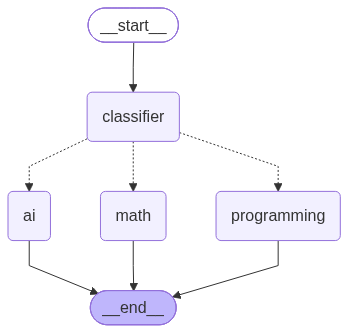

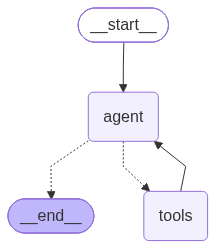

In [35]:
from IPython.display import Image, display

def show_graph(g):
    try:
        display(Image(g.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("PNG rendering unavailable:", e)
        print(g.get_graph().draw_mermaid())

show_graph(router_graph)
show_graph(tool_graph)

## Evaluating the behavior of an agentic workflow

A minimal evaluation harness: define test cases with expected categories, run them, and compute accuracy. You can extend this with tool-call checks, latency, and cost.

In [36]:
import time

test_cases = [
    ("What is the derivative of x²?", "mathematics"),
    ("Solve 2x + 3 = 11", "mathematics"),
    ("How do I reverse a list in Python?", "programming"),
    ("Write a function to check for palindromes.", "programming"),
    ("What is a convolutional neural network?", "artificial_intelligence"),
    ("Explain overfitting.", "artificial_intelligence"),
]

correct, rows = 0, []
for q, expected in test_cases:
    t0 = time.time()
    out = router_graph.invoke({"question": q, "category": "", "answer": ""})
    got = out["category"]
    ok = expected in got
    correct += ok
    rows.append((q, expected, got, ok, round(time.time() - t0, 2)))

import pandas as pd
df = pd.DataFrame(rows, columns=["question", "expected", "got", "correct", "seconds"])
display(df)
print(f"Routing accuracy: {correct}/{len(test_cases)} = {correct/len(test_cases):.0%}")

,question,expected,got,correct,seconds
0,What is the derivative of x²?,mathematics,mathematics,True,7.48
1,Solve 2x + 3 = 11,mathematics,mathematics,True,3.49
2,How do I reverse a list in Python?,programming,programming,True,12.47
3,Write a function to check for palindromes.,programming,programming,True,9.43
4,What is a convolutional neural network?,artificial_intelligence,artificial_intelligence,True,15.38
5,Explain overfitting.,artificial_intelligence,artificial_intelligence,True,16.66


Routing accuracy: 6/6 = 100%


**Discussion:** Where did the router fail (if anywhere)? What would make the routing more robust (structured output, few-shot examples, enum validation)?

**Your answer:** 
*The router did not fail on any of the six test cases giving an accuracy of six out of six which equals one hundred percent. However the router’s result should be read with caution. The test set is small. Each question clearly fits into one category. Ambiguous questions, such as the question "Write a program to compute the derivative of x² " which mixes mathematics and programming or short questions were not tested. A free router at temperature zero can still produce outputs, from run to run. The router’s evaluation also uses a check meaning the router accepts a malformed label if that label merely contains the expected word.*

There is various improvements would help to make the routing more robust:
1. **Structured output**: use `llm.with_structured_output()` with a Pydantic model or `Literal["mathematics", "programming", "artificial_intelligence"]` – in other words, force the model to produce a valid category rather than free-form text.
2. **Few-shot examples** in the classifier prompt, specifically for ambiguous cases.
3. **Enum validation with fallback**: validate the produced label against the acceptable set and fall back to a safe branch (as was done in the capstone project with the GENERAL/fallback approach).
4. **A more difficult test set** that includes ambiguous and out-of-scope questions, an exact-match test rather than substring match, and multiple iterations to estimate variance.

## PART X — Capstone project: Intelligent University Assistant

### Requirements covered below
| # | Requirement | Implementation |
|---|---|---|
| 1 | Question classifier | `classify` node → COURSES / PROGRAMMING / MATHEMATICS / ADMINISTRATION / GENERAL |
| 2 | Specialized agents | one node per category, built with `make_agent` |
| 3 | Memory | `MemorySaver` checkpointer + `thread_id` |
| 4 | Tools | `calculator`, `current_datetime` (+ optional extras) |
| 5 | Conditional routing | `route_after_classifier`, `route_after_agent`, `route_after_tools` |
| 6 | Error handling | empty input, unknown category, invalid tool calls, API errors |

### Architecture
```
User question → Classifier ─┬→ Courses Agent ──────┐
                            ├→ Programming Agent ──┤
                            ├→ Mathematics Agent ──┼→ Tool decision ─→ Tools (Calculator / Date-time / ...)
                            ├→ Administration Agent┤        │                │
                            ├→ General Agent ──────┘        ▼                │
                            └→ Fallback (empty/error)   Final response ◄─────┘
```
Each agent decides whether to call a tool; after the tool runs, control returns to the **same** agent, which writes the final response.

In [50]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

CATEGORIES = ["COURSES", "PROGRAMMING", "MATHEMATICS", "ADMINISTRATION", "GENERAL"]

class AssistantState(TypedDict):
    messages: Annotated[list, add_messages]
    category: str

### 1. Classifier (with error handling)

In [51]:
def classify(state: AssistantState):
    last = state["messages"][-1]
    text = (last.content if hasattr(last, "content") else str(last)).strip()

    # Error handling: empty question
    if not text:
        return {"category": "EMPTY"}

    prompt = f"""
    Classify the student's question into exactly one category:
    COURSES (course content, syllabus, schedules, exams, grading),
    PROGRAMMING, MATHEMATICS,
    ADMINISTRATION (enrollment, fees, certificates, procedures, deadlines),
    GENERAL (anything else).

    Question: {text}

    Return only the category name.
    """
    try:
        raw = llm.invoke(prompt).content.strip().upper()
    except Exception as e:                      # Error handling: API errors
        print("Classifier API error:", e)
        return {"category": "ERROR"}

    # Error handling: unknown/unexpected label -> GENERAL
    category = next((c for c in CATEGORIES if c in raw), "GENERAL")
    return {"category": category}

### 2. Specialized agents (factory) + fallback node

In [52]:
SYSTEM_PROMPTS = {
    "COURSES": "You are a university courses advisor. Explain course content, prerequisites, "
               "schedules and study strategies. If you lack institution-specific data, say so honestly.",
    "PROGRAMMING": "You are a programming tutor. Give clear explanations and correct Python code when appropriate.",
    "MATHEMATICS": "You are a mathematics tutor. Show steps. ALWAYS use the calculator tool for arithmetic.",
    "ADMINISTRATION": "You are a university administration assistant (enrollment, fees, certificates, procedures). "
                      "Never invent official rules or deadlines; recommend contacting the administration office when unsure.",
    "GENERAL": "You are a helpful university assistant. Use the date/time tool for questions about the current date or time.",
}

def make_agent(category: str):
    system = SystemMessage(content=SYSTEM_PROMPTS[category])

    def node(state: AssistantState):
        try:
            response = llm_with_tools.invoke([system] + state["messages"])
            return {"messages": [response]}
        except Exception as e:                  # Error handling: API errors
            return {"messages": [AIMessage(
                content=f"Sorry, I ran into a technical problem while answering ({type(e).__name__}). Please try again."
            )]}
    return node

def fallback(state: AssistantState):
    if state["category"] == "EMPTY":
        msg = "Your question seems to be empty. Please type a question and I'll help."
    else:
        msg = "Sorry, I couldn't process your question right now. Please try again in a moment."
    return {"messages": [AIMessage(content=msg)]}

### 3. Routing functions and graph assembly

`ToolNode(..., handle_tool_errors=True)` converts invalid tool calls / tool exceptions into error messages the agent can recover from, instead of crashing the graph.

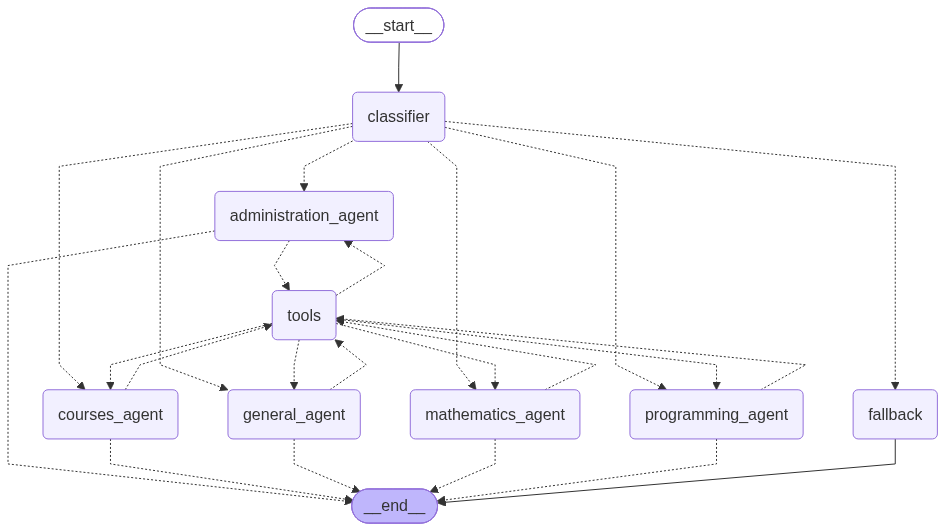

In [67]:
NODE_NAMES = {c: f"{c.lower()}_agent" for c in CATEGORIES}

def route_after_classifier(state: AssistantState):
    return NODE_NAMES.get(state["category"], "fallback")

def route_after_agent(state: AssistantState):
    last = state["messages"][-1]
    return "tools" if getattr(last, "tool_calls", None) else END

def route_after_tools(state: AssistantState):
    # return to the agent that requested the tool
    return NODE_NAMES.get(state["category"], "general_agent")

builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
show_graph(assistant)

### 4. Demonstration — at least 5 different user queries
Includes: all categories, both tools, memory, and error cases (empty input).

In [57]:
def ask(question: str, thread_id: str = "demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = assistant.invoke({"messages": [HumanMessage(content=question)]}, config)
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", result["category"])
    print("ASSISTANT:", result["messages"][-1].content)
    return result

demo_queries = [
    "What topics are usually covered in a machine learning course?",     # COURSES
    "Write a Python function that computes the factorial of n.",         # PROGRAMMING
    "What is 125 * 38 + 17?",                                            # MATHEMATICS (calculator)
    "How do I request an enrollment certificate?",                       # ADMINISTRATION
    "What is today's date?",                                             # GENERAL (date/time tool)
    "   ",                                                               # Error: empty question
]
for q in demo_queries:
    ask(q)

USER    : What topics are usually covered in a machine learning course?
CATEGORY: COURSES
ASSISTANT: A typical university-level machine learning course usually covers the following topics, though the exact content varies by institution and level (undergraduate vs. graduate):

## Core Topics

**Foundations & Preliminaries**
- Supervised vs. unsupervised vs. reinforcement learning
- Bias-variance tradeoff, overfitting/underfitting
- Train/validation/test splits, cross-validation
- Evaluation metrics (accuracy, precision, recall, F1, ROC-AUC, MSE, R²)

**Supervised Learning**
- Linear and logistic regression
- k-Nearest Neighbors (k-NN)
- Decision trees and random forests
- Support Vector Machines (SVM)
- Naïve Bayes
- Neural networks / multi-layer perceptrons (introductory)
- Gradient descent and optimization basics

**Unsupervised Learning**
- k-means clustering
- Hierarchical clustering
- Principal Component Analysis (PCA) and dimensionality reduction
- Gaussian mixture models
- Associ

In [58]:
# Memory test: same thread_id
ask("My name is Ahmed.", thread_id="memory-test")
ask("What is my name?", thread_id="memory-test");

USER    : My name is Ahmed.
CATEGORY: GENERAL
ASSISTANT: Hello Ahmed! Nice to meet you. How can I help you today?
USER    : What is my name?
CATEGORY: GENERAL
ASSISTANT: Your name is Ahmed.


In [59]:
# Inspect the full message trace (including tool calls) of one run
r = assistant.invoke(
    {"messages": [HumanMessage(content="Compute (15 + 27) * 3 using the calculator.")]},
    {"configurable": {"thread_id": "trace"}},
)
for m in r["messages"]:
    m.pretty_print()

================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================
Tool Calls:
  calculator (call-1ff766ac-de84-45d6-b580-b0114beb67e7)
 Call ID: call-1ff766ac-de84-45d6-b580-b0114beb67e7
  Args:
    expression: (15 + 27) * 3
================================= Tool Message =================================
Name: calculator

126
================================== Ai Message ==================================

**Step 1:** Evaluate the expression inside the parentheses first.  
15 + 27 = 42

**Step 2:** Multiply the result by 3.  
42 × 3 = 126

**Final Answer:**  
(15 + 27) × 3 = **126**


### 5. Optional extensions
Add one or more of: Wikipedia, web search, a database (e.g. SQLite with course data), a PDF reader, or weather. Implement each as a `@tool`, append it to the `tools` list **before** calling `llm.bind_tools(...)`, and rebuild the graph.

```python
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
wiki = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
```

In [68]:
import requests
from urllib.parse import quote
from langchain_core.tools import tool

WIKI_HEADERS = {"User-Agent": "LangGraphLab/1.0 (university lab exercise)"}

@tool
def wikipedia_search(query: str) -> str:
    """Search Wikipedia and return a short summary of the best matching article.
    Use for factual questions about people, places, concepts or history."""
    try:
        r = requests.get(
            "https://en.wikipedia.org/w/api.php",
            params={"action": "query", "list": "search", "srsearch": query,
                    "srlimit": 1, "format": "json"},
            headers=WIKI_HEADERS, timeout=10,
        )
        r.raise_for_status()
        hits = r.json()["query"]["search"]
        if not hits:
            return "No Wikipedia article found."
        title = hits[0]["title"]
        s = requests.get(
            "https://en.wikipedia.org/api/rest_v1/page/summary/" + quote(title.replace(" ", "_"), safe=""),
            headers=WIKI_HEADERS, timeout=10,
        )
        s.raise_for_status()
        return f"{title}: {s.json().get('extract', '')[:1500]}"
    except Exception as e:
        return f"Wikipedia lookup failed: {type(e).__name__}"

tools = [calculator, current_datetime, wikipedia_search]
llm_with_tools = llm.bind_tools(tools)

In [69]:
ask("Who created the Python programming language? Use the Wikipedia tool.", thread_id="wiki-test")

USER    : Who created the Python programming language? Use the Wikipedia tool.
CATEGORY: PROGRAMMING
ASSISTANT: The Python programming language was created by **Guido van Rossum**, a Dutch programmer. He developed Python in the late 1980s and released the first version in 1991. Van Rossum served as Python’s “benevolent dictator for life” (BDFL) until he stepped down from that role in July 2018.


{'messages': [HumanMessage(content='Who created the Python programming language? Use the Wikipedia tool.', additional_kwargs={}, response_metadata={}, id='bbf43cb0-f88c-43cb-82dd-cc990b3c12c6'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 77, 'prompt_tokens': 441, 'total_tokens': 518, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 47, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3.5-super-vl:free', 'system_fingerprint': None, 'id': 'gen-1793458631-K2AdDMidyYRCmmM7

In [70]:
tests = [
    ("trace-2", "Compute (15 + 27) * 3 using the calculator."),
    ("wiki-test-2", "Who created the Python programming language? Use the Wikipedia tool."),
]

for tid, q in tests:
    r = assistant.invoke(
        {"messages": [HumanMessage(content=q)]},
        {"configurable": {"thread_id": tid}},
    )
    print("=" * 70)
    print("Q:", q)
    for m in r["messages"]:
        m.pretty_print()

Q: Compute (15 + 27) * 3 using the calculator.
================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================
Tool Calls:
  calculator (call-d3ef7dbc-dff0-404f-abd0-bd54fc6b6baf)
 Call ID: call-d3ef7dbc-dff0-404f-abd0-bd54fc6b6baf
  Args:
    expression: (15 + 27) * 3
================================= Tool Message =================================
Name: calculator

126
================================== Ai Message ==================================

**Step 1:** Evaluate the expression inside the parentheses first.  
\(15 + 27 = 42\)

**Step 2:** Multiply the result by 3.  
\(42 \times 3 = 126\)

**Answer:**  
\((15 + 27) \times 3 = 126\)
Q: Who created the Python programming language? Use the Wikipedia tool.
================================ Human Message =================================

Who created the Python programming language? Use the Wik

## Deliverables checklist

- [ ] `langgraph_lab.ipynb` (this notebook, executed, with outputs)
- [ ] `README.md` (setup, how to run, design choices)
- [ ] Source code
- [ ] Architecture diagram (export from `show_graph(assistant)` or Mermaid)
- [ ] Screenshots showing execution
- [ ] Short report answering the conceptual questions